# L0 step 2 · A top-up training of our 7B at full size (GPU T4 ×2)

Task **L0**, step 2, from `Essential_task_delegation/Next_Steps_Roadmap.md`.
- Decided 19 Oct 2026: a short extra training at full size on disaster type (DTR) and relational reasoning (ORR), with an equal replay sample of the other tasks. Both models are then judged on every optical question.
- Decided 20 Oct: it runs on account 3, after the old model's re-score (`l0-step2-full-size-rescore.ipynb`, part A).

Built from `support/Abrar/Implementation_DisasterM3/train_qwen_disasterm3_ddp.ipynb`, which stays unchanged: the same recipe (the DisasterM3 paper's Appendix B.3), rewritten for today's Kaggle libraries.

**Why**
- L0 step 1: testing at full size raised DTR from 71.1% to 75.6% and ORR from 23.3% to 31.1%. The paper's fine-tune of the same model reaches 83.6% and 36.2%.
- We trained with images capped at 616 px (484 tokens) and test at 1036 px (1,369 tokens). Training at the size we test at may close more of the gap.

**What changes from the original run**

| Setting | Original (CSE499A) | This run |
|---|---|---|
| Starts from | Qwen2.5-VL-7B-Instruct | our 7B, merged (`AbrarAlam/disasterm3-qwen2.5vl7b-mergedFP`), held in 4-bit |
| Adapter | LoRA rank 64, alpha 16, dropout 0.05, language model only (161,480,704 parameters) | the same, as a new adapter on the merged model |
| Optimiser | AdamW, lr 2e-4, β 0.9 / 0.95, cosine, 3% warmup, weight decay 0.01, clipping 1.0 | the same |
| Batch | 256 (1 × 128 accumulation × 2 GPUs), 1 epoch | the same: about 28 optimizer steps |
| Images | capped at 616 px (512 × 28 × 28 pixels) | full size, as the evaluation feeds them: 1036 px for a 1024 px image, never more |
| Data | the 55,764 Instruct entries with a text answer | DTR 1,627 + ORR 1,882, plus 3,509 replayed from the other six tasks (seed 42): 7,018 |
| Loss | the answer tokens only | the same; the output layer runs only over the answer, to save memory |
| Precision | fp16 on a 4-bit NF4 base; embeddings and output layer upcast to fp32 | the same, except that the embeddings and output layer stay fp16, so full-size images fit on a T4 |
| Libraries | torch 2.4.1, transformers 4.49, trl 0.13 (no longer installable on Kaggle's Python 3.13) | Kaggle's torch and transformers, current peft and bitsandbytes, the plain Trainer |

**Why a new adapter on the merged model**, not the old adapter's weights (a technical change from the plan):
- The old adapter (`checkpoint-217`) picks its layers with a pattern written for transformers 4.49 (`model.layers.N`). Transformers 5 names them `model.language_model.layers.N`, so the pattern matches nothing.
- The merged model holds the base plus the old adapter and loads cleanly in transformers 5 (H1 V2, L0 step 1). A new adapter trained on it starts from exactly our 7B; Cell 6 merges it in.

**Expectation, fixed before the run**
- DTR and ORR rise by a few points (about 1–4). A 28-step top-up is unlikely to close the paper's gaps (8.0 and 5.1 points) on its own.
- The other four tasks stay within about a point, because the replay keeps them in training.
- **Keep rule** (fixed 19 Oct), applied with the re-score notebook to all six tasks at full size: keep the new model only if DTR and ORR rise and no other task drops by more than 1 point.

**Time:** the smoke test measures it. The original notebook estimated 25–50 minutes per 512 examples at 616 px on one T4. Full-size examples are about 2.6 times longer, which suggests about 7–14 hours for the 7,018 on two T4s. After 10 hours of training the run saves, pushes and stops; running it again continues from Hugging Face.

**How to run on Kaggle** (account 3)
1. Settings: **GPU T4 ×2**, internet ON.
2. Input: the DisasterM3 mirror `abrarmohammedtanzim/disasterm3-mirror`.
3. Secret `HF_TOKEN` (AbrarAlam, **write** access).
   - Checkpoints go to the private repo `AbrarAlam/disasterm3-qwen25vl7b-qlora`, under `l0s2/checkpoints/`.
   - The merged model goes to `AbrarAlam/disasterm3-qwen2.5vl7b-l0s2-mergedFP`, public like our first merged 7B. Set `MERGED_PUBLIC = False` in Cell 2 to keep it private.
4. Smoke test: set `SMOKE_TEST = True` in Cell 2, then Run All. It runs 16 examples (the longest included) in 2 optimizer steps, in about 25 minutes with the 16 GB download. Cell 5 reports the loss, the peak GPU memory and the projected hours for the full run. Only a small config file is pushed.
5. Full run: set `SMOKE_TEST = False`, then Save & Run All. If it stops at the time limit, run it again with the same settings: Cell 2 restores the latest checkpoint from Hugging Face.
6. When training is complete, Cell 6 merges the adapter into our 7B and pushes it. Then run `l0-step2-full-size-rescore.ipynb` with `MODEL = "new"`.
   - To merge in a CPU session instead, run Cells 1, 2 and 6.
7. Outputs in `/kaggle/working/L0S2-train/`: `config.json`, `train.py`, `train_summary.json`, `loss_curve.png`, `README.md`, and the last two checkpoints (also on Hugging Face).

In [1]:
# ── Cell 1: Environment: Kaggle's torch and transformers, plus current peft and bitsandbytes ──
# The original pinned torch 2.4.1, transformers 4.49 and trl 0.13, which have no wheels for Kaggle's Python 3.13.
# This keeps Kaggle's torch and transformers, upgrades the two QLoRA libraries, and doesn't use trl.
import importlib.metadata as _md
import subprocess
import sys

subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-U", "peft", "bitsandbytes"], check=True)

def _version(pkg):
    try:
        return _md.version(pkg)
    except _md.PackageNotFoundError:
        return "0"

assert int(_version("transformers").split(".")[0]) >= 5, "written for transformers 5 (Kaggle's 5.16.1 on 20 Oct)"

import torch
VERSIONS = {p: _version(p) for p in ("torch", "transformers", "peft", "bitsandbytes", "accelerate")}
print(f"✓ {VERSIONS}, python {sys.version.split()[0]}")
print(f"  GPUs: {[torch.cuda.get_device_name(i) for i in range(torch.cuda.device_count())]}")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 835.4/835.4 kB 3.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 38.7 MB/s eta 0:00:00
✓ {'torch': '2.11.0+cu128', 'transformers': '5.16.1', 'peft': '0.21.2', 'bitsandbytes': '0.50.2', 'accelerate': '1.14.0'}, python 3.13.15
  GPUs: ['Tesla T4', 'Tesla T4']


In [2]:
# ── Cell 2: Configuration, Hugging Face access, the starting model in the cache, and the latest checkpoint ──
import json
import os
import shutil
from pathlib import Path

from huggingface_hub import HfApi, snapshot_download

SMOKE_TEST = False             # True = 16 examples (the longest included), 2 optimizer steps: memory and time check
REPLAY_RATIO = 1.0             # replayed examples of the other tasks per DTR/ORR example (19 Oct: an equal sample)
MERGED_PUBLIC = True           # like our first merged 7B, whose repo is public
WORK = Path("/kaggle/working/L0S2-train")
CFG = {
    "task": "L0 step 2: top-up training at full size",
    "smoke_test": SMOKE_TEST,
    "start_model": "AbrarAlam/disasterm3-qwen2.5vl7b-mergedFP",         # our 7B (CSE499A), merged
    "merged_repo": "AbrarAlam/disasterm3-qwen2.5vl7b-l0s2-mergedFP",    # the result, merged by Cell 6
    "merged_public": MERGED_PUBLIC,
    "adapter_repo": "AbrarAlam/disasterm3-qwen25vl7b-qlora",            # private; the original adapter lives here too
    "hub_dir": "l0s2/checkpoints",                                      # this run's checkpoints in it
    "data_root": "/kaggle/input/datasets/abrarmohammedtanzim/disasterm3-mirror/DisasterM3_Instruct",
    "output_dir": str(WORK / ("smoke" if SMOKE_TEST else "checkpoints")),
    "focus_tasks": ["Disaster Type Recognition", "relational reasoning"],   # as the training manifest names them
    "replay_ratio": REPLAY_RATIO,
    "seed": 42,
    "max_pixels": 1369 * 28 * 28,        # 1036 x 1036: full size for a 1024 px image, never more
    "lora": {"r": 64, "alpha": 16, "dropout": 0.05},
    "lr": 2e-4, "betas": [0.9, 0.95], "weight_decay": 0.01, "warmup_ratio": 0.03,
    "per_device_batch": 1,
    "grad_accum": 4 if SMOKE_TEST else 128,     # x 2 GPUs: a global batch of 256, as in the original (smoke test: 8)
    "save_steps": 4,                     # roughly every 1.5-2 hours
    "time_limit_h": 0.3,                 # session 3a (22 Oct, account 3's last 1 h 26 min): one step only (25), then save and push
    # 21 Oct: the same 8-bit AdamW without paging. The paged one crashed on resume: the saved optimizer state keeps
    # bitsandbytes' "is_paged" flag, so it prefetched ordinary GPU memory ("invalid argument" in cprefetch).
    "optim": "adamw_bnb_8bit",
    "smoke_examples": 16,
}
WORK.mkdir(parents=True, exist_ok=True)
(WORK / "config.json").write_text(json.dumps(CFG, indent=1), encoding="utf-8")

try:
    from kaggle_secrets import UserSecretsClient
    os.environ["HF_TOKEN"] = UserSecretsClient().get_secret("HF_TOKEN")     # the training processes read it too
except Exception as e:
    raise RuntimeError("Add the HF_TOKEN secret (AbrarAlam, write access)") from e
api = HfApi(token=os.environ["HF_TOKEN"])
api.upload_file(path_or_fileobj=str(WORK / "config.json"), path_in_repo="l0s2/config.json",
                repo_id=CFG["adapter_repo"], commit_message="L0 step 2: config")    # also checks write access

start = snapshot_download(CFG["start_model"], token=os.environ["HF_TOKEN"])    # both processes load from this cache
print(f"✓ L0 step 2{'  [SMOKE TEST]' if SMOKE_TEST else ''}: config written and pushed; starting model cached at {start}")

# Continue a stopped run: its latest checkpoint from Hugging Face (never in the smoke test)
out, prefix = Path(CFG["output_dir"]), CFG["hub_dir"] + "/"
steps = sorted({int(f[len(prefix):].split("/")[0].split("-")[1])
                for f in api.list_repo_files(CFG["adapter_repo"]) if f.startswith(prefix + "checkpoint-")})
if steps and not SMOKE_TEST and not (out / f"checkpoint-{steps[-1]}").exists():
    name = f"checkpoint-{steps[-1]}"
    local = snapshot_download(CFG["adapter_repo"], allow_patterns=[f"{prefix}{name}/*"], token=os.environ["HF_TOKEN"])
    shutil.copytree(Path(local) / CFG["hub_dir"] / name, out / name)
    print(f"✓ Continuing from {name}, restored from Hugging Face")
else:
    print("Starting fresh" if SMOKE_TEST or not steps else f"✓ checkpoint-{steps[-1]} is already here")


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 17 files:   0%|          | 0/17 [00:00<?, ?it/s]

✓ L0 step 2: config written and pushed; starting model cached at /root/.cache/huggingface/hub/models--AbrarAlam--disasterm3-qwen2.5vl7b-mergedFP/snapshots/8553f6e620d2b31702bb3d3847e13a3e8c0e3747


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 10 files:   0%|          | 0/10 [00:00<?, ?it/s]

✓ Continuing from checkpoint-24, restored from Hugging Face


In [3]:
%%writefile /kaggle/working/L0S2-train/train.py
# ── Cell 3 (written to train.py): L0 step 2's training, one process per T4, launched by Cell 4 ──
import os
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")
import json
import math
import random
import time
from collections import Counter
from importlib.metadata import version
from pathlib import Path

import torch
from huggingface_hub import HfApi
from peft import LoraConfig, get_peft_model
from PIL import Image
from transformers import (AutoProcessor, BitsAndBytesConfig, Qwen2_5_VLForConditionalGeneration, Trainer,
                          TrainerCallback, TrainingArguments)

WORK = Path("/kaggle/working/L0S2-train")
CFG = json.loads((WORK / "config.json").read_text(encoding="utf-8"))
SMOKE = CFG["smoke_test"]
RANK, WORLD = int(os.environ.get("LOCAL_RANK", "0")), int(os.environ.get("WORLD_SIZE", "1"))
MAIN = RANK == 0
torch.cuda.set_device(RANK)
api = HfApi(token=os.environ.get("HF_TOKEN"))

def log(msg):
    if MAIN:
        print(msg, flush=True)

# ── Data: DTR and ORR, plus a replay sample of the other tasks, as the original notebooks built them ──
DATA_ROOT = Path(CFG["data_root"])
PATH_SUFFIXES = (".png", ".jpg", ".jpeg", ".tif", ".tiff")

def resolve(rel_path):
    """A manifest path -> its file in the mirror, by the training notebooks' rule (None if missing)."""
    if not rel_path:
        return None
    rel_path = rel_path.replace("\\", "/")
    name = Path(rel_path).name
    for p in (DATA_ROOT / rel_path, DATA_ROOT / "train_images" / rel_path, DATA_ROOT / "box_train_images" / rel_path,
              DATA_ROOT / "train_images" / "train_images" / name,
              DATA_ROOT / "box_train_images" / "box_train_images" / name):
        if p.exists():
            return str(p)
    return None

def first(x):
    return (x[0] if x else "") if isinstance(x, list) else x

def answer_of(e):
    return str(first(e.get("training_answer", ""))).strip()

def example(e):
    """The images (before and after, or the boxed image), the training prompt and the training answer;
    None if an image is missing."""
    keys = ["image_path"] if "image_path" in e else ["pre_image_path", "post_image_path"]
    paths = [resolve(e.get(k, "")) for k in keys]
    if not all(paths):
        return None
    return {"images": paths, "prompt": str(first(e.get("prompts", ""))), "answer": answer_of(e), "task": e["task"]}

raw = json.load(open(DATA_ROOT / "train_release.json", encoding="utf-8"))
usable = [e for e in raw if e.get("task") != "Referring Expression Segmentation"     # masks, no text answer
          and answer_of(e) and not answer_of(e).lower().endswith(PATH_SUFFIXES)]
focus = [e for e in usable if e["task"] in CFG["focus_tasks"]]
pool = [e for e in usable if e["task"] not in CFG["focus_tasks"]]
replay = random.Random(CFG["seed"]).sample(pool, round(CFG["replay_ratio"] * len(focus)))
examples = [x for x in map(example, focus + replay) if x]
by_task = dict(Counter(x["task"] for x in examples))
missing = len(focus) + len(replay) - len(examples)
longest = max(examples, key=lambda x: (len(x["images"]), len(x["answer"])))   # the longest sequence
if SMOKE:       # the longest example (peak memory) and a random sample of the rest (time per example)
    rest = [x for x in examples if x is not longest]
    examples = [longest] + random.Random(CFG["seed"]).sample(rest, CFG["smoke_examples"] - 1)
log(f"✓ Data: {sum(by_task.values()):,} examples {by_task}; missing images: {missing}"
    + (f"; SMOKE TEST: {len(examples)} of them" if SMOKE else ""))

# ── Model: our merged 7B held in 4-bit, with a new LoRA adapter on the language model only ──
model = Qwen2_5_VLForConditionalGeneration.from_pretrained(
    CFG["start_model"], dtype=torch.float16, device_map={"": RANK}, attn_implementation="sdpa",
    quantization_config=BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                                           bnb_4bit_compute_dtype=torch.float16, bnb_4bit_use_double_quant=True))
PROJECTIONS = ("q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj")
targets = [n for n, _ in model.named_modules() if n.rsplit(".", 1)[-1] in PROJECTIONS and "visual" not in n]
assert len(targets) == 28 * 7, f"expected the 196 language-model projections, found {len(targets)}"
model.enable_input_require_grads()      # gradient checkpointing needs a gradient path from the inputs
model = get_peft_model(model, LoraConfig(r=CFG["lora"]["r"], lora_alpha=CFG["lora"]["alpha"],
                                         lora_dropout=CFG["lora"]["dropout"], target_modules=targets,
                                         bias="none", task_type="CAUSAL_LM"))
trainable = [p for p in model.parameters() if p.requires_grad]
assert sum(p.numel() for p in trainable) == 161_480_704, "not the original's 161,480,704 LoRA parameters"
assert all(p.dtype == torch.float32 for p in trainable), "LoRA weights must be fp32 under fp16 mixed precision"
log(f"✓ Model: 4-bit on {WORLD} GPUs; LoRA on {len(targets)} language-model projections, vision tower untouched; "
    f"{torch.cuda.memory_allocated() / 1e9:.1f} GB on GPU {RANK}")

# ── Batches: full-size images, the chat template, and the loss on the answer only ──
processor = AutoProcessor.from_pretrained(CFG["start_model"])     # the stock Qwen2.5-VL processor: full size
tok = processor.tokenizer
MARKER = tok("<|im_start|>assistant\n", add_special_tokens=False)["input_ids"]
VISION_IDS = torch.tensor([tok.convert_tokens_to_ids(t) for t in ("<|image_pad|>", "<|vision_start|>", "<|vision_end|>")])

def smart_resize(height, width, min_pixels, max_pixels, factor=28):
    """Qwen2.5-VL's rule for the size an image reaches the model at (its image processor's smart_resize)."""
    h, w = round(height / factor) * factor, round(width / factor) * factor
    if h * w > max_pixels:
        beta = math.sqrt(height * width / max_pixels)
        h, w = math.floor(height / beta / factor) * factor, math.floor(width / beta / factor) * factor
    elif h * w < min_pixels:
        beta = math.sqrt(min_pixels / (height * width))
        h, w = math.ceil(height * beta / factor) * factor, math.ceil(width * beta / factor) * factor
    return h, w

def sized(img):
    """The native image, as the evaluation feeds it; only an image above 1036 x 1036 is scaled down."""
    if img.width * img.height <= CFG["max_pixels"]:
        return img
    h, w = smart_resize(img.height, img.width, 56 * 56, CFG["max_pixels"])
    return img.resize((w, h), Image.BICUBIC)

def mask_prompt(row):
    """No loss up to and including the last assistant header: the loss is on the answer only, as in the original."""
    ids = row.tolist()
    for start in range(len(ids) - len(MARKER), -1, -1):
        if ids[start:start + len(MARKER)] == MARKER:
            row[:start + len(MARKER)] = -100
            return row
    raise ValueError("no assistant turn in the sequence")

def collate(batch):
    texts, images = [], []
    for x in batch:
        imgs = [sized(Image.open(p).convert("RGB")) for p in x["images"]]
        messages = [{"role": "user", "content": [{"type": "image"} for _ in imgs] + [{"type": "text", "text": x["prompt"]}]},
                    {"role": "assistant", "content": [{"type": "text", "text": x["answer"]}]}]
        texts.append(processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=False))
        images += imgs
    out = processor(text=texts, images=images, padding=True, return_tensors="pt")
    labels = out["input_ids"].clone()
    labels[out["attention_mask"] == 0] = -100
    for row in labels:
        mask_prompt(row)
    assert not torch.isin(labels, VISION_IDS).any(), "image tokens in the loss"
    # The output layer (152k words) runs only from the token before the first answer token to the end. The model's
    # own loss shifts these labels by one, exactly as over the whole sequence; at full size this saves 2-4 GB.
    keep = labels.shape[1] - int((labels != -100).int().argmax(1).min()) + 1
    out["labels"], out["logits_to_keep"] = labels[:, -keep:], keep
    return out

probe = collate([longest])
log(f"✓ Longest example: {probe['input_ids'].shape[1]:,} tokens, {int(probe['image_grid_thw'].prod(1).sum()) // 4:,} "
    f"of them image tokens; the loss covers its last {probe['logits_to_keep'] - 1}")

# ── Training: the original recipe; every checkpoint goes to Hugging Face; a clean stop before Kaggle's limit ──
class Clock(TrainerCallback):
    """Times every optimizer step; past the time limit it saves (and so pushes) and stops."""
    def __init__(self):
        self.start = self.last = time.time()
        self.step_seconds = []
    def on_step_end(self, args, state, control, **kwargs):
        now = time.time()
        self.step_seconds.append(round(now - self.last, 1))
        self.last = now
        if now - self.start > CFG["time_limit_h"] * 3600 and state.global_step < state.max_steps:
            log(f"⏰ Time limit after step {state.global_step}: saving, pushing and stopping")
            control.should_save, control.should_training_stop = True, True
        return control

class PushToHub(TrainerCallback):
    """Each saved checkpoint goes to the adapter repo; Cell 2 restores the latest one in a new session."""
    def on_save(self, args, state, control, **kwargs):
        if MAIN:
            name = f"checkpoint-{state.global_step}"
            api.upload_folder(folder_path=str(Path(args.output_dir) / name), repo_id=CFG["adapter_repo"],
                              path_in_repo=f"{CFG['hub_dir']}/{name}", commit_message=f"L0 step 2: {name}")
            log(f"✓ Pushed {name} to {CFG['adapter_repo']}/{CFG['hub_dir']}")

GLOBAL = WORLD * CFG["per_device_batch"] * CFG["grad_accum"]
steps = math.ceil(len(examples) / GLOBAL)
args = TrainingArguments(
    output_dir=CFG["output_dir"], num_train_epochs=1, per_device_train_batch_size=CFG["per_device_batch"],
    gradient_accumulation_steps=CFG["grad_accum"], learning_rate=CFG["lr"], adam_beta1=CFG["betas"][0],
    adam_beta2=CFG["betas"][1], weight_decay=CFG["weight_decay"], lr_scheduler_type="cosine",
    warmup_steps=math.ceil(CFG["warmup_ratio"] * steps), max_grad_norm=1.0, fp16=True,
    gradient_checkpointing=True, gradient_checkpointing_kwargs={"use_reentrant": False},
    logging_steps=1, save_strategy="steps", save_steps=CFG["save_steps"], save_total_limit=2, report_to="none", optim=CFG["optim"],
    dataloader_num_workers=2, remove_unused_columns=False, ddp_find_unused_parameters=False, seed=CFG["seed"])

class StepOnCpu(Trainer):
    """The trainer collects all 128 micro-batches of a step before training on any, and the data loader has
    already put each one on the GPU: with full-size images that ran out of memory (20 Oct). Keep the waiting
    batches on the CPU (images in fp16, the dtype the model casts them to); training_step moves each back in turn."""
    def get_batch_samples(self, epoch_iterator, *args, **kwargs):
        to_cpu = ({k: (v.to("cpu", torch.float16) if k == "pixel_values" else v.cpu()) if torch.is_tensor(v) else v
                   for k, v in b.items()} for b in epoch_iterator)
        return super().get_batch_samples(to_cpu, *args, **kwargs)

clock = Clock()
trainer = StepOnCpu(model=model, args=args, train_dataset=examples, data_collator=collate,
                    callbacks=[clock] + ([] if SMOKE else [PushToHub()]))
saved = sorted(Path(CFG["output_dir"]).glob("checkpoint-*"), key=lambda p: int(p.name.split("-")[1]))
resume = str(saved[-1]) if saved and not SMOKE else None
log(f"⏳ Training {len(examples):,} examples in about {steps} optimizer steps of {GLOBAL}"
    + (f", continuing from {resume}" if resume else ""))
trainer.train(resume_from_checkpoint=resume)

# ── What the run did, for Cell 5 ──
peak = torch.cuda.max_memory_allocated() / 1e9
print(f"[GPU {RANK}] peak memory {peak:.1f} GB", flush=True)
if MAIN:
    state = trainer.state
    per_example = clock.step_seconds[-1] / GLOBAL if clock.step_seconds else None
    summary = {
        "smoke_test": SMOKE, "examples": len(examples), "full_examples": sum(by_task.values()), "by_task": by_task,
        "missing_images": missing, "global_step": state.global_step, "max_steps": state.max_steps,
        "complete": state.global_step >= state.max_steps, "resumed_from": resume,
        "longest_tokens": int(probe["input_ids"].shape[1]), "peak_gpu_memory_gb_gpu0": round(peak, 2),
        "step_seconds": clock.step_seconds, "seconds_per_example": per_example and round(per_example, 2),
        "projected_full_hours": per_example and round(per_example * sum(by_task.values()) / 3600, 1),
        "log_history": state.log_history,
        "versions": {p: version(p) for p in ("torch", "transformers", "peft", "bitsandbytes", "accelerate")}}
    (WORK / f"train_summary{'_smoke' if SMOKE else ''}.json").write_text(json.dumps(summary, indent=1))
    log(f"✓ Step {state.global_step} of {state.max_steps}{' (complete)' if summary['complete'] else ''}; "
        f"{per_example and round(per_example, 1)} s per example on the last step")


Writing /kaggle/working/L0S2-train/train.py


In [4]:
# ── Cell 4: Train, one process per T4 (DDP); the output streams below ──
assert torch.cuda.device_count() >= 2, "Pick GPU T4 x2"
!accelerate launch --multi_gpu --num_processes=2 /kaggle/working/L0S2-train/train.py

The following values were not passed to `accelerate launch` and had defaults used instead:
	`--num_machines` was set to a value of `1`
	`--mixed_precision` was set to a value of `'no'`
	`--dynamo_backend` was set to a value of `'no'`
To avoid this warning pass in values for each of the problematic parameters or run `accelerate config`.
✓ Data: 7,018 examples {'Disaster Type Recognition': 1627, 'relational reasoning': 1882, 'disaster restoration advice': 533, 'Disaster Bearing Bodies Recognition': 510, 'Disaster Scene Recognition': 477, 'Building Damage Counting': 958, 'disaster caption': 535, 'Road Damage Counting': 496}; missing images: 0
Reconstructing (incomplete total...): |            |  0.00B /  0.00B            

Fetching 4 files: 100%|█████████████████████████| 4/4 [00:00<00:00, 1225.15it/s]
Download complete: :                                        |  0.00B            
Reconstructing (incomplete total...): |            |  0.00B /  0.00B            

Fetching 4 files: 100%|███

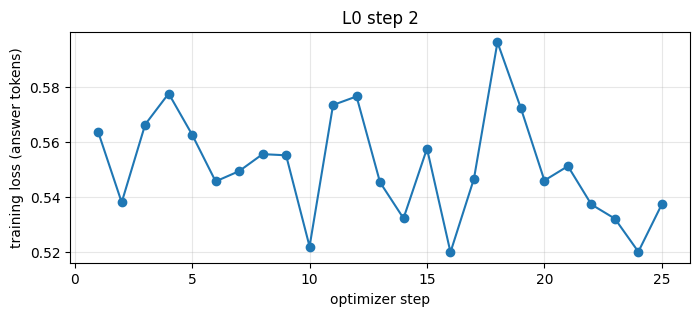

- Steps: 25 of 28 (not complete: run the notebook again to continue)
- Examples: 7,018 (full run: 7,018, {'Disaster Type Recognition': 1627, 'relational reasoning': 1882, 'disaster restoration advice': 533, 'Disaster Bearing Bodies Recognition': 510, 'Disaster Scene Recognition': 477, 'Building Damage Counting': 958, 'disaster caption': 535, 'Road Damage Counting': 496}); missing images: 0
- Longest example: 3,092 tokens; peak GPU memory on GPU 0: 14.26 GB
- Losses: [0.563, 0.538, 0.566, 0.577, 0.563, 0.546, 0.549, 0.555, 0.555, 0.522, 0.573, 0.576, 0.545, 0.532, 0.557, 0.52, 0.547, 0.596, 0.572, 0.546, 0.551, 0.537, 0.532, 0.52, 0.537]
- Last step: 9.93 s per example on both GPUs; projected for all 7,018 examples: 19.4 h
- Versions: {'torch': '2.11.0+cu128', 'transformers': '5.16.1', 'peft': '0.21.2', 'bitsandbytes': '0.50.2', 'accelerate': '1.14.0'}

✓ Wrote README.md and loss_curve.png to /kaggle/working/L0S2-train


In [5]:
# ── Cell 5: What the run did: the loss, memory and time, and a README ──
import matplotlib.pyplot as plt

S_PATH = WORK / ("train_summary_smoke.json" if SMOKE_TEST else "train_summary.json")
assert S_PATH.exists(), f"No {S_PATH.name}: the training stopped early; read Cell 4's output"
S = json.loads(S_PATH.read_text(encoding="utf-8"))
losses = [(e["step"], e["loss"]) for e in S["log_history"] if "loss" in e]
if losses:
    plt.figure(figsize=(8, 3))
    plt.plot(*zip(*losses), marker="o")
    plt.xlabel("optimizer step")
    plt.ylabel("training loss (answer tokens)")
    plt.title("L0 step 2" + (" (smoke test)" if SMOKE_TEST else ""))
    plt.grid(alpha=0.3)
    plt.savefig(WORK / "loss_curve.png", dpi=120, bbox_inches="tight")
    plt.show()

lines = [
    f"- Steps: {S['global_step']} of {S['max_steps']} "
    f"({'complete' if S['complete'] else 'not complete: run the notebook again to continue'})",
    f"- Examples: {S['examples']:,} (full run: {S['full_examples']:,}, {S['by_task']}); "
    f"missing images: {S['missing_images']}",
    f"- Longest example: {S['longest_tokens']:,} tokens; peak GPU memory on GPU 0: {S['peak_gpu_memory_gb_gpu0']} GB",
    f"- Losses: {[round(loss, 3) for _, loss in losses]}",
    f"- Last step: {S['seconds_per_example']} s per example on both GPUs; projected for all "
    f"{S['full_examples']:,} examples: {S['projected_full_hours']} h",
    f"- Versions: {S['versions']}",
]
if SMOKE_TEST:
    lines += ["", "How to read the smoke test:",
              "- Loss: about 0.4-1.2 is the original run's level (it ended at 0.55). Above 3, the labels are misaligned.",
              "- Peak memory under about 14 GB leaves room on a T4 (15 GB).",
              "- Over 10 projected hours, the full run takes two sessions (it continues from Hugging Face)."]
print("\n".join(lines))
(WORK / "README.md").write_text("\n".join([
    f"# L0 step 2: top-up training of our 7B at full size{' (SMOKE TEST)' if SMOKE_TEST else ''}", "",
    f"From `{CFG['start_model']}` (held in 4-bit), a new LoRA adapter (rank 64, alpha 16) on the language model, "
    f"trained on disaster type and relational reasoning plus a replay sample of the other tasks, at full size "
    f"(up to 1036 x 1036). The original recipe otherwise: lr 2e-4, cosine, global batch "
    f"{2 * CFG['grad_accum']}, 1 epoch.", "",
    *lines, "",
    f"Checkpoints: `{CFG['adapter_repo']}/{CFG['hub_dir']}`. Merged result (Cell 6): `{CFG['merged_repo']}`.",
]), encoding="utf-8")
print(f"\n✓ Wrote README.md{' and loss_curve.png' if losses else ''} to {WORK}")

In [6]:
# ── Cell 6: Merge the finished adapter into our 7B and push it (only once training is complete) ──
saved = sorted(Path(CFG["output_dir"]).glob("checkpoint-*"), key=lambda p: int(p.name.split("-")[1]))
state = json.loads((saved[-1] / "trainer_state.json").read_text(encoding="utf-8")) if saved else {}
if SMOKE_TEST or not saved or state.get("global_step") != state.get("max_steps"):
    print("Not merging: " + ("smoke test" if SMOKE_TEST else
                             f"training isn't complete (step {state.get('global_step')} of {state.get('max_steps')})"))
else:
    import gc
    from peft import PeftModel
    from transformers import AutoProcessor, Qwen2_5_VLForConditionalGeneration

    print(f"⏳ Merging {saved[-1].name} into {CFG['start_model']} (fp16, on the CPU, as the first merge was done)...")
    base = Qwen2_5_VLForConditionalGeneration.from_pretrained(CFG["start_model"], dtype=torch.float16, device_map="cpu")
    merged = PeftModel.from_pretrained(base, str(saved[-1])).merge_and_unload()
    MERGED_DIR = Path("/tmp/l0s2_merged")          # 16 GB: /kaggle/working keeps only the outputs
    merged.save_pretrained(MERGED_DIR)
    AutoProcessor.from_pretrained(CFG["start_model"]).save_pretrained(MERGED_DIR)   # the stock processor: full size
    api.create_repo(CFG["merged_repo"], private=not CFG["merged_public"], exist_ok=True)
    api.upload_folder(folder_path=str(MERGED_DIR), repo_id=CFG["merged_repo"],
                      commit_message=f"L0 step 2: {saved[-1].name} merged into our 7B")
    del base, merged
    gc.collect()
    print(f"✓ Pushed {CFG['merged_repo']}. Next: l0-step2-full-size-rescore.ipynb with MODEL = \"new\".")

Not merging: training isn't complete (step 25 of 28)
